# Monitor de Coyuntura: Inflación en Chile

**Pregunta de proyección:** ¿Cuál será la trayectoria de la inflación interanual en Chile durante los próximos 12 a 24 meses?

**Integrantes:** Joaquín González, Vicente Montecinos, Benjamín Paredes y Giordano Mazzarelli

Este notebook lee la base `data/coyuntura.db` creada por `src/carga_db.py`. Todos los cálculos (paso a frecuencia mensual, variaciones y rezagos) se hacen en SQL, en `sql/03_consultas_inflacion.sql`, y aquí solo se leen con `src/consultas.py` para revisarlos y graficarlos.

In [1]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

# Permite importar los módulos de src/ (el notebook se ejecuta desde la raíz del repo)
sys.path.insert(0, str(Path("src").resolve()))
from consultas import consulta, crear_vistas, FECHA_CORTE

pd.set_option("display.width", 160)
plt.rcParams["figure.figsize"] = (10, 4.5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

FUENTE_BCCH = "Banco Central de Chile (Base de Datos Estadísticos)"
FUENTE_FRED = "FRED, Federal Reserve Bank of St. Louis"


def periodo(fechas):
    """Texto con el período que cubre un gráfico, por ejemplo '01-2011 a 09-2026'."""
    return f"{fechas.min():%m-%Y} a {fechas.max():%m-%Y}"


def pie(fig, fuente, per):
    """Escribe la fuente y el período debajo del gráfico."""
    fig.text(0.01, 0.01, f"Fuente: {fuente}. Período: {per}.", fontsize=8, color="gray")
    fig.tight_layout(rect=(0, 0.04, 1, 1))


print("Fecha de corte:", FECHA_CORTE)

Fecha de corte: 2026-09-30


## 1. Revisión de la base de datos

Antes de analizar, revisamos qué quedó en la base: cuántas observaciones tiene cada serie y entre qué fechas. Una serie con 0 observaciones indicaría una extracción fallida, y una fecha final antigua, una serie descontinuada.


In [2]:
# Una fila por serie: cuántos datos tiene y entre qué fechas (consulta revision_base del archivo SQL)
consulta("revision_base")

,tema,nombre,frecuencia,unidad,n_obs,desde,hasta
0,Actividad,Imacec,M,índice 2018=100,200,2010-01-01,2026-08-01
1,Actividad,Imacec Desestacionalizado,M,índice 2018=100,200,2010-01-01,2026-08-01
2,Internacional,IPC Estados Unidos,M,índice 1982-84=100,200,2010-01-01,2026-09-01
3,Internacional,Tasa Fed Funds (EE.UU.),M,% anual,201,2010-01-01,2026-09-01
4,Internacional,Tasa de Bonos del Tesoro EE.UU. 10 años,M,% anual,201,2010-01-01,2026-09-01
5,Internacional,Índice Dólar Global (Nominal Broad),D,índice ene-2006=100,4170,2010-01-04,2026-09-30
6,Mercado laboral,Tasa de Desempleo,M,% fuerza de trabajo,198,2010-03-01,2026-08-01
7,Política monetaria,Tasa de Política Monetaria (TPM),D,% anual,4172,2010-01-04,2026-09-30
8,Precios,IPC Alimentos,M,índice 2023=100,201,2010-01-01,2026-09-01
9,Precios,IPC General Empalmado,M,índice 2023=100,201,2010-01-01,2026-09-01


In [3]:
# Controles de calidad: duplicados, observaciones huérfanas y valores del modo demo. Todos deben ser 0.
consulta("chequeo_integridad")

,duplicados,huerfanas,valores_demo
0,0,0,0


**Resultado de la revisión:** las 13 series se cargaron correctamente y todas tienen datos recientes (hasta agosto o septiembre de 2026). Las series mensuales parten en 2010, salvo el precio del cobre, que en la base del Banco Central comienza en octubre de 2012. Los tres controles de calidad dan 0: no hay observaciones duplicadas, ni datos de series que no estén en el catálogo, ni valores del modo demo.

Las series diarias (TPM, tipo de cambio, cobre e índice dólar) se llevan a frecuencia mensual promediando los días de cada mes, en la vista `v_mensual` del archivo SQL.

## 2. Variable objetivo: inflación a 12 meses

La inflación anual se calcula en SQL a partir del índice del IPC (vista `v_cambios`): la variación porcentual del índice respecto del mismo mes del año anterior. Para validar el cálculo, lo comparamos con la variación mensual oficial que publica el Banco Central (columna `dif_vs_oficial`, que debe ser cercana a 0).

In [4]:
# Crea las vistas v_mensual y v_cambios en la base (paso a mensual, variaciones y rezagos en SQL)
crear_vistas()

inflacion = consulta("inflacion")
inflacion.tail(12)

,mes,ipc_indice,inflacion_mensual,inflacion_12m,desvio_meta_pp,var_mensual_oficial,dif_vs_oficial
189,2025-10-01,109.19,0.05,3.44,0.44,0.0,0.05
190,2025-11-01,109.47,0.26,3.44,0.44,0.3,-0.04
191,2025-12-01,109.26,-0.19,3.45,0.45,-0.2,0.01
192,2026-01-01,109.71,0.41,2.78,-0.22,0.4,0.01
193,2026-02-01,109.70,-0.01,2.37,-0.63,0.0,-0.01
194,2026-03-01,110.75,0.96,2.83,-0.17,1.0,-0.04
195,2026-04-01,112.18,1.29,3.96,0.96,1.3,-0.01
196,2026-05-01,112.37,0.17,3.93,0.93,0.2,-0.03
197,2026-06-01,112.35,-0.02,4.34,1.34,0.0,-0.02
198,2026-07-01,112.45,0.09,3.53,0.53,0.1,-0.01


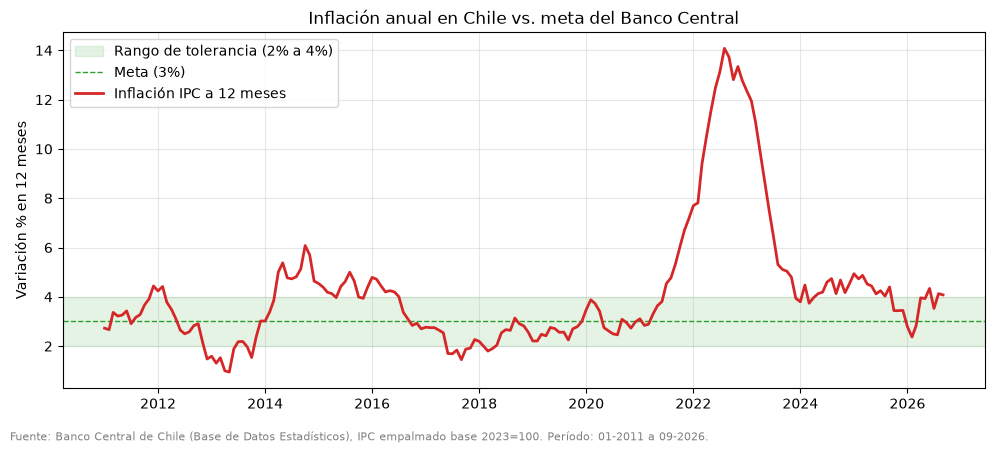

In [5]:
g = inflacion.dropna(subset=["inflacion_12m"])

fig, ax = plt.subplots()
ax.axhspan(2, 4, color="tab:green", alpha=0.12, label="Rango de tolerancia (2% a 4%)")
ax.axhline(3, color="tab:green", ls="--", lw=1, label="Meta (3%)")
ax.plot(g["mes"], g["inflacion_12m"], color="tab:red", lw=2, label="Inflación IPC a 12 meses")
ax.set_title("Inflación anual en Chile vs. meta del Banco Central")
ax.set_ylabel("Variación % en 12 meses")
ax.legend(loc="upper left")
pie(fig, FUENTE_BCCH + ", IPC empalmado base 2023=100", periodo(g["mes"]))
plt.show()

**Lectura:** entre 2011 y 2020 la inflación se mantuvo en general cerca del rango de tolerancia del Banco Central (2% a 4%), con una excepción entre 2014 y 2016, cuando superó el 4% y llegó a cerca de 6%. A partir de 2021 se produjo un fuerte shock inflacionario que llevó la inflación a un máximo de alrededor de 14% a mediados de 2022, el nivel más alto del período. Luego bajó rápidamente durante 2023, pero entre 2024 y 2025 se mantuvo levemente sobre el techo de 4%.

A comienzos de 2026 la inflación cayó dentro del rango (2,4% en febrero), pero volvió a subir desde marzo, con un alza mensual de 1,3% en abril. En septiembre de 2026 la inflación a 12 meses es de **4,1%**, 1,1 puntos sobre la meta y justo en el límite superior del rango. Las siguientes secciones buscan explicar qué está detrás de este repunte.

In [6]:
# Inflación promedio de cada año y meses fuera del rango de tolerancia (GROUP BY por año)
consulta("resumen_anual")

,anio,inflacion_12m_promedio,minimo,maximo,meses_sobre_4,meses_bajo_2,meses_con_dato
0,2011,3.34,2.67,4.44,1,0,12
1,2012,3.01,1.48,4.42,2,1,12
2,2013,1.80,0.95,3.02,0,8,12
3,2014,4.71,3.02,6.08,9,0,12
4,2015,4.35,3.94,5.00,9,0,12
5,2016,3.80,2.70,4.79,7,0,12
6,2017,2.18,1.45,2.77,0,6,12
7,2018,2.44,1.80,3.14,0,3,12
8,2019,2.56,2.21,2.99,0,0,12
9,2020,3.05,2.46,3.88,0,0,12


**Lectura:** entre 2011 y 2020 la inflación promedio anual fue de 3% o menos en la mayoría de los años. Los años de inflación baja se concentraron en 2013, 2017 y 2018, con meses bajo el 2%, y los de inflación alta en 2014 a 2016. Desde 2021 el escenario cambió: de los 69 meses entre enero de 2021 y septiembre de 2026, **50 estuvieron sobre el 4%**, y no hubo ninguno bajo el 2%. En 2022 los 12 meses superaron el techo, con un promedio de 11,6%.

En 2024 y 2025 la inflación bajó, pero siguió sobre el rango en 9 de cada 12 meses (promedio de 4,3% y 4,2%). En 2026 el promedio hasta septiembre es de 3,6%, pero 3 de los 9 meses ya superan el 4%, lo que confirma el repunte de los últimos meses.

## 3. Factores que explican la inflación

Para entender la trayectoria de la inflación revisamos sus principales determinantes: los precios de los alimentos, la política monetaria (TPM), el tipo de cambio, la actividad y el mercado laboral, y el contexto externo. Todas las series se llevan a frecuencia mensual en SQL. Las que son índices o niveles se expresan como variación % en 12 meses, y las que son tasas se muestran en su nivel.

In [7]:
# Panel mensual de todas las series, en formato ancho (una columna por serie)
panel = consulta("panel_mensual")
var12 = panel.pivot(index="mes", columns="nombre", values="cambio_12m")  # var. % 12m (o diferencia en pp si es tasa)
nivel = panel.pivot(index="mes", columns="nombre", values="valor")        # valor promedio del mes
var12.columns.tolist()

['IPC Alimentos',
 'IPC Estados Unidos',
 'IPC General Empalmado',
 'IPC Variación Mensual',
 'Imacec',
 'Imacec Desestacionalizado',
 'Precio del Cobre',
 'Tasa Fed Funds (EE.UU.)',
 'Tasa de Bonos del Tesoro EE.UU. 10 años',
 'Tasa de Desempleo',
 'Tasa de Política Monetaria (TPM)',
 'Tipo de Cambio Observado (CLP/USD)',
 'Índice Dólar Global (Nominal Broad)']

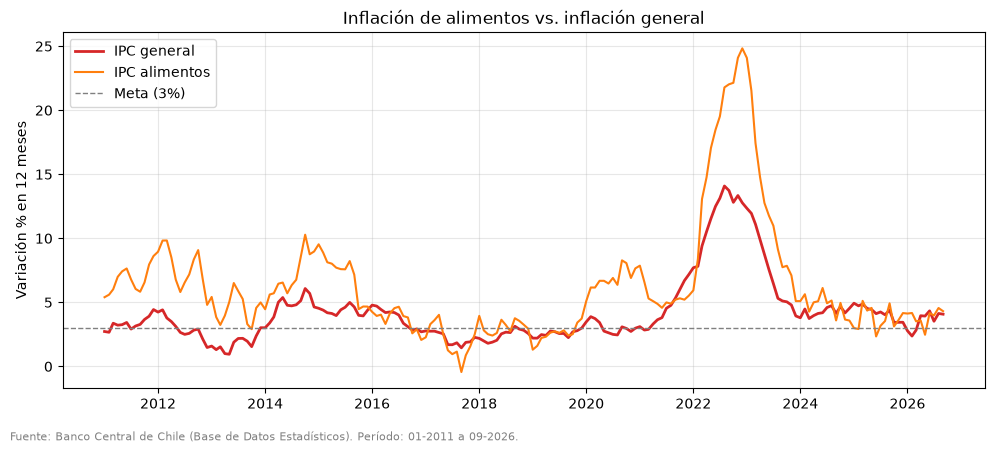

In [8]:
d = var12[["IPC General Empalmado", "IPC Alimentos"]].dropna()

fig, ax = plt.subplots()
ax.plot(d.index, d["IPC General Empalmado"], color="tab:red", lw=2, label="IPC general")
ax.plot(d.index, d["IPC Alimentos"], color="tab:orange", lw=1.5, label="IPC alimentos")
ax.axhline(3, color="gray", ls="--", lw=1, label="Meta (3%)")
ax.set_title("Inflación de alimentos vs. inflación general")
ax.set_ylabel("Variación % en 12 meses")
ax.legend(loc="upper left")
pie(fig, FUENTE_BCCH, periodo(d.index))
plt.show()

**Lectura:** la inflación de alimentos es mucho más volátil que la inflación general y suele adelantarse a sus movimientos. Estuvo sobre la inflación general en los episodios de alza (2011-2012, 2014-2015 y 2020-2023), lo que indica que los alimentos empujaron la inflación en esos períodos. El caso más claro es el shock de 2022, cuando la inflación de alimentos llegó a cerca de 25% a fines de ese año, casi el doble que el IPC general.

Desde 2024 ambas series se mueven juntas, en torno a 4% a 5%. En 2026 la inflación de alimentos es similar a la general (alrededor de 4%), por lo que **el repunte reciente no se explica principalmente por los alimentos**, sino por presiones más amplias en la canasta.

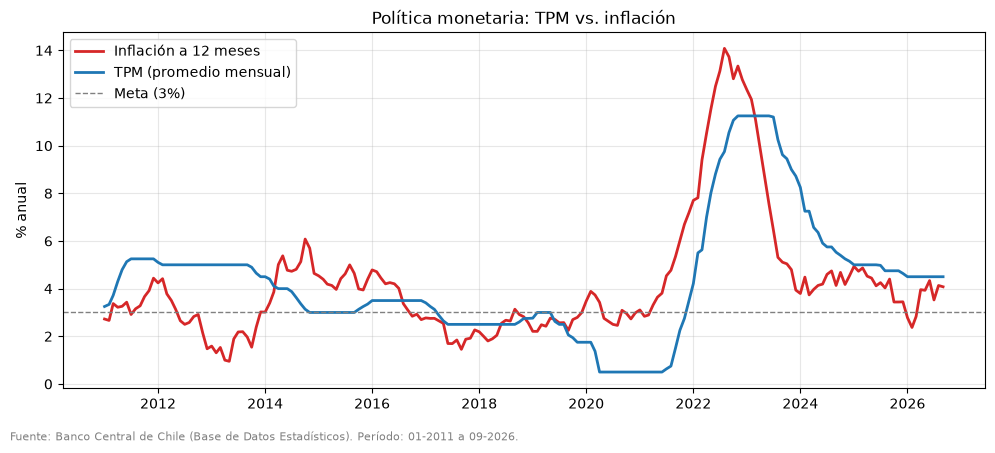

In [9]:
d = pd.concat([var12["IPC General Empalmado"].rename("inflacion"),
               nivel["Tasa de Política Monetaria (TPM)"].rename("tpm")], axis=1).dropna()

fig, ax = plt.subplots()
ax.plot(d.index, d["inflacion"], color="tab:red", lw=2, label="Inflación a 12 meses")
ax.plot(d.index, d["tpm"], color="tab:blue", lw=2, label="TPM (promedio mensual)")
ax.axhline(3, color="gray", ls="--", lw=1, label="Meta (3%)")
ax.set_title("Política monetaria: TPM vs. inflación")
ax.set_ylabel("% anual")
ax.legend(loc="upper left")
pie(fig, FUENTE_BCCH, periodo(d.index))
plt.show()

**Lectura:** la TPM responde a la inflación con rezago. Durante la pandemia, el Banco Central bajó la tasa a su mínimo de 0,5% (2020 a mediados de 2021) para apoyar la actividad. Cuando la inflación comenzó a subir en 2021, inició uno de los ciclos de alza más fuertes de su historia y llevó la TPM a 11,25% a fines de 2022, manteniéndola en ese nivel hasta mediados de 2023. La inflación empezó a bajar unos meses después de alcanzar ese nivel de tasa, lo que es consistente con el efecto rezagado de la política monetaria.

Desde mediados de 2023 la TPM se fue recortando gradualmente hasta cerca de 4,5% en 2026, donde se ha mantenido estable. Con una inflación de 4,1%, la **tasa real (TPM menos inflación) es cercana a 0,4 puntos**, una postura apenas restrictiva. Si la inflación sigue sobre el 4%, el Banco Central tendría poco espacio para seguir bajando la tasa en los próximos meses.

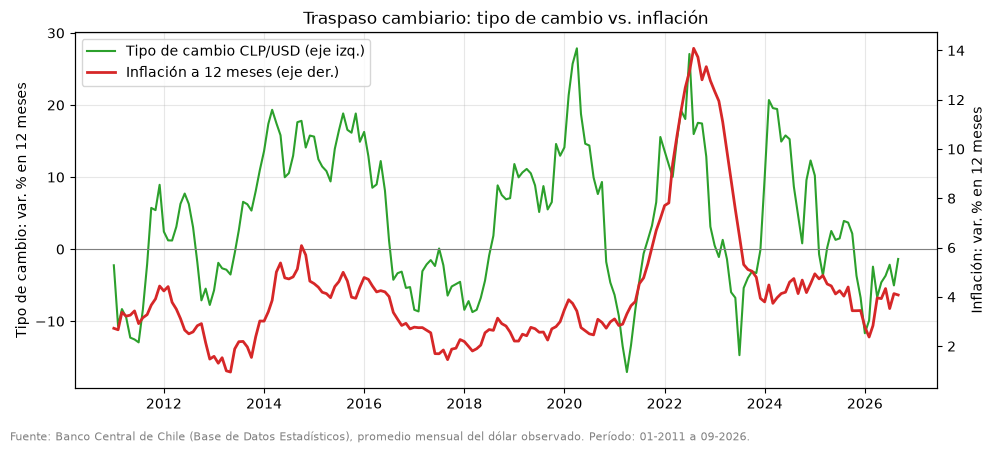

In [10]:
d = pd.concat([var12["IPC General Empalmado"].rename("inflacion"),
               var12["Tipo de Cambio Observado (CLP/USD)"].rename("dolar")], axis=1).dropna()

fig, ax = plt.subplots()
ax.plot(d.index, d["dolar"], color="tab:green", lw=1.5, label="Tipo de cambio CLP/USD (eje izq.)")
ax.axhline(0, color="gray", lw=0.8)
ax.set_ylabel("Tipo de cambio: var. % en 12 meses")
ax2 = ax.twinx()
ax2.plot(d.index, d["inflacion"], color="tab:red", lw=2, label="Inflación a 12 meses (eje der.)")
ax2.set_ylabel("Inflación: var. % en 12 meses")
ax2.grid(False)
ax.set_title("Traspaso cambiario: tipo de cambio vs. inflación")
lineas = ax.get_lines()[:1] + ax2.get_lines()
ax.legend(lineas, [l.get_label() for l in lineas], loc="upper left")
pie(fig, FUENTE_BCCH + ", promedio mensual del dólar observado", periodo(d.index))
plt.show()

**Lectura:** una depreciación del peso (alza del dólar) encarece los bienes importados y tiende a subir la inflación con algunos meses de rezago; es el llamado traspaso cambiario. Se observa en 2014-2015, cuando el dólar subió entre 15% y 19% anual y la inflación superó el 4%, y en 2021-2022, cuando una depreciación cercana a 27% coincidió con el máximo de inflación.

Sin embargo, el traspaso no es automático: en 2020 el dólar subió cerca de 28% anual y la inflación casi no reaccionó, porque la pandemia deprimió la demanda. Lo mismo ocurrió a comienzos de 2024 (alza de ~20%), con una inflación que se mantuvo en torno a 4%-5%.

En 2026 el peso se **apreció** respecto de un año antes (el dólar llegó a caer ~10% anual a comienzos de año, y hoy su variación es cercana a 0%). Esto coincide con la baja de la inflación a inicios de 2026, pero **no explica el repunte posterior**: el tipo de cambio hoy no está presionando la inflación al alza.

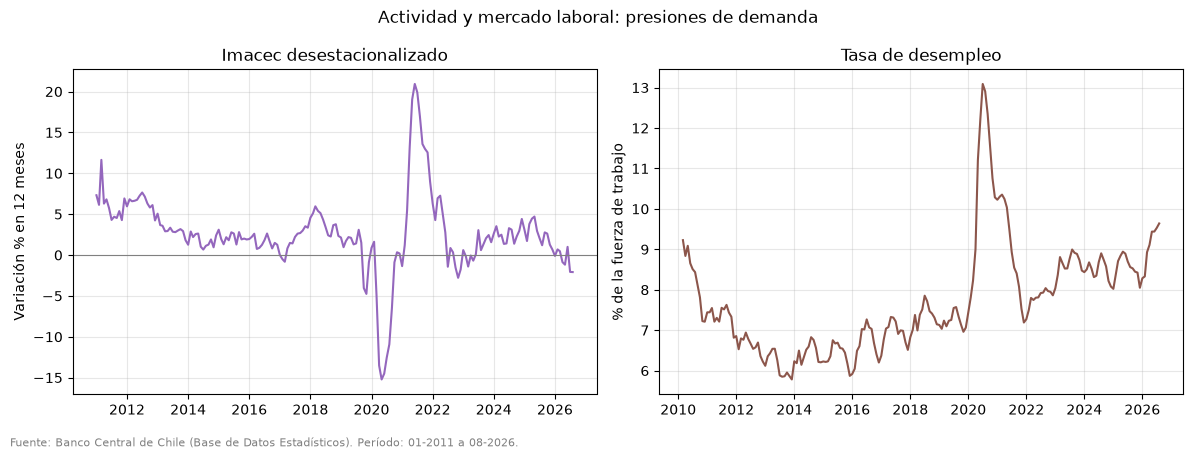

In [11]:
imacec = var12["Imacec Desestacionalizado"].dropna()
desempleo = nivel["Tasa de Desempleo"].dropna()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ax1.plot(imacec.index, imacec, color="tab:purple", lw=1.5)
ax1.axhline(0, color="gray", lw=0.8)
ax1.set_title("Imacec desestacionalizado")
ax1.set_ylabel("Variación % en 12 meses")
ax2.plot(desempleo.index, desempleo, color="tab:brown", lw=1.5)
ax2.set_title("Tasa de desempleo")
ax2.set_ylabel("% de la fuerza de trabajo")
fig.suptitle("Actividad y mercado laboral: presiones de demanda")
pie(fig, FUENTE_BCCH, periodo(imacec.index))
plt.show()

**Lectura:** una economía que crece rápido y con bajo desempleo genera presiones de demanda que elevan la inflación. Esto se vio en 2021: tras la caída de la pandemia (Imacec cerca de -15% anual y desempleo sobre 13% en 2020), la actividad rebotó con fuerza, llegando a crecer cerca de 21% anual a mediados de 2021, impulsada por los estímulos fiscales y los retiros de fondos de pensiones. Ese exceso de demanda antecedió el alza de la inflación a 14% en 2022.

La situación actual es la opuesta. En 2026 el Imacec desestacionalizado muestra una **caída de alrededor de 2% anual** a mediados de año, y la tasa de desempleo subió hasta cerca de **9,6%**, su nivel más alto desde 2021. La economía está perdiendo dinamismo, por lo que **el repunte de la inflación no viene de un exceso de demanda**. Al contrario, una actividad débil y un mercado laboral holgado deberían ayudar a moderar la inflación en los próximos meses.

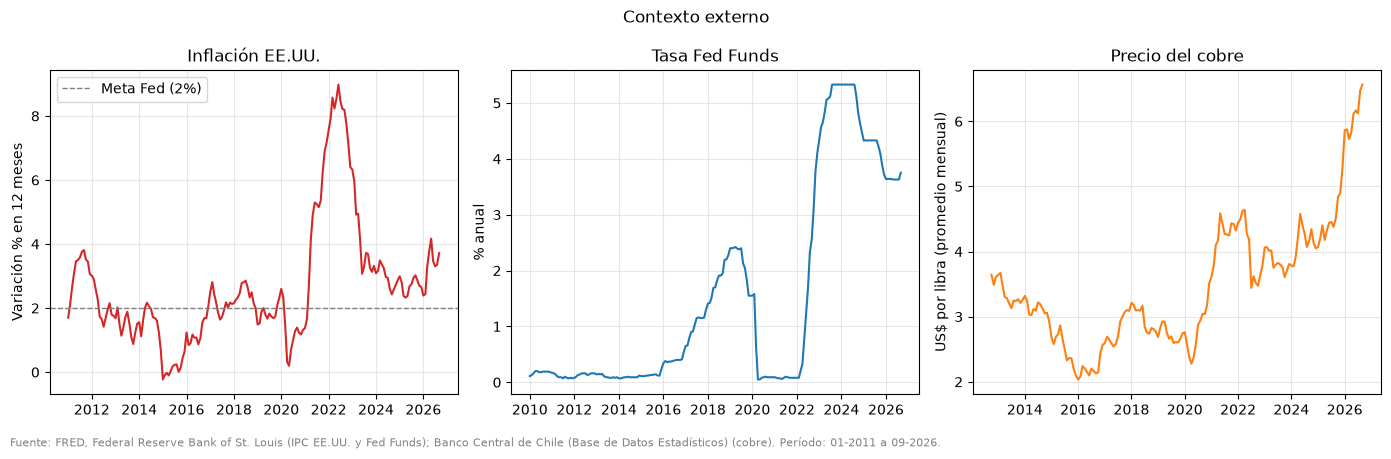

In [12]:
# El IPC de EE.UU. no tiene dato de oct-2025 (no se publicó por el cierre del gobierno de EE.UU.).
# Se calcula la variación 12m sobre la serie con todos los meses, así solo queda vacío oct-2025.
ipc_eeuu = (nivel["IPC Estados Unidos"].pct_change(12, fill_method=None) * 100).dropna()
fed = nivel["Tasa Fed Funds (EE.UU.)"].dropna()
cobre = nivel["Precio del Cobre"].dropna()

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(14, 4.5))
ax1.plot(ipc_eeuu.index, ipc_eeuu, color="tab:red", lw=1.5)
ax1.axhline(2, color="gray", ls="--", lw=1, label="Meta Fed (2%)")
ax1.set_title("Inflación EE.UU.")
ax1.set_ylabel("Variación % en 12 meses")
ax1.legend(loc="upper left")
ax2.plot(fed.index, fed, color="tab:blue", lw=1.5)
ax2.set_title("Tasa Fed Funds")
ax2.set_ylabel("% anual")
ax3.plot(cobre.index, cobre, color="tab:orange", lw=1.5)
ax3.set_title("Precio del cobre")
ax3.set_ylabel("US$ por libra (promedio mensual)")
fig.suptitle("Contexto externo")
pie(fig, FUENTE_FRED + " (IPC EE.UU. y Fed Funds); " + FUENTE_BCCH + " (cobre)", periodo(ipc_eeuu.index))
plt.show()

**Lectura:** el contexto externo afecta a Chile por tres canales. Primero, la **inflación de EE.UU.** encarece los bienes que Chile importa. Tras su máximo de cerca de 9% en 2022, bajó a alrededor de 3% en 2024-2025, pero en 2026 volvió a subir hasta cerca de 4%. Este repunte coincide con el de la inflación chilena, lo que sugiere que parte de las presiones actuales son **importadas**.

Segundo, la **tasa de la Fed** condiciona los flujos de capital hacia economías emergentes. La Fed la subió a 5,3% en 2023 y luego comenzó a recortarla hasta cerca de 3,6%, pero en 2026 detuvo los recortes ante el repunte de la inflación en EE.UU. Una Fed menos expansiva limita el espacio del Banco Central de Chile para bajar la TPM sin depreciar el peso.

Tercero, el **precio del cobre**, principal exportación de Chile, alcanzó máximos históricos en 2026, sobre 6,5 US$ por libra. Un cobre alto fortalece el peso y mejora los ingresos fiscales, lo que es consistente con la apreciación del peso observada en 2026 y actúa como un factor que **modera** la inflación.

*Nota sobre los datos:* el IPC de EE.UU. de octubre de 2025 no fue publicado por el cierre del gobierno de EE.UU. Como el cálculo en SQL deja la variación vacía cuando falta un mes, para esta serie la variación en 12 meses se calculó en Python sobre la serie completa, de modo que solo octubre de 2025 queda sin dato.

## 4. Tabla de coyuntura

Último dato disponible de cada serie, con su variación en 12 meses actual y la de hace 3 meses, para ver qué indicadores se están acelerando o desacelerando. Para las tasas (TPM, Fed, bono a 10 años y desempleo), el cambio se mide en puntos porcentuales.

In [13]:
# Último dato de cada serie y si se está acelerando (cambio 12m hoy vs. hace 3 meses)
consulta("tabla_coyuntura")

,tema,nombre,unidad,tipo,ultimo_mes,ultimo_valor,cambio_12m,cambio_12m_hace_3m
0,Actividad,Imacec,índice 2018=100,nivel,2026-08-01,109.08,-1.01,-1.39
1,Actividad,Imacec Desestacionalizado,índice 2018=100,nivel,2026-08-01,110.86,-2.08,-1.18
2,Internacional,IPC Estados Unidos,índice 1982-84=100,nivel,2026-09-01,336.30,NaN,NaN
3,Internacional,Tasa Fed Funds (EE.UU.),% anual,tasa,2026-09-01,3.75,-0.47,-0.70
4,Internacional,Tasa de Bonos del Tesoro EE.UU. 10 años,% anual,tasa,2026-09-01,4.99,0.87,0.09
5,Internacional,Índice Dólar Global (Nominal Broad),índice ene-2006=100,nivel,2026-09-01,119.22,-0.68,-0.42
6,Mercado laboral,Tasa de Desempleo,% fuerza de trabajo,tasa,2026-08-01,9.64,1.08,0.49
7,Política monetaria,Tasa de Política Monetaria (TPM),% anual,tasa,2026-09-01,4.50,-0.25,-0.50
8,Precios,IPC Alimentos,índice 2023=100,nivel,2026-09-01,114.66,4.31,4.16
9,Precios,IPC General Empalmado,índice 2023=100,nivel,2026-09-01,113.59,4.08,4.34


**Lectura:** el último dato muestra dos grupos de indicadores que empujan en direcciones opuestas.

**Presiones al alza:**
- La inflación está en **4,1% anual** (septiembre 2026), en el techo del rango, y la de alimentos en 4,3%.
- La inflación de EE.UU. se mantiene cerca de 4% (ver sección 3; en esta tabla aparece vacía por la falta del dato de octubre de 2025).
- La tasa del bono del Tesoro a 10 años subió **0,87 puntos en un año**, hasta 5,0%, lo que refleja condiciones financieras globales más estrechas.
- La TPM está en 4,5%, apenas sobre la inflación, por lo que la política monetaria es solo levemente restrictiva.

**Presiones a la baja:**
- La actividad se está contrayendo: el Imacec desestacionalizado cae **2,1% anual** (agosto 2026), y su caída se profundizó respecto de hace 3 meses (-1,2%).
- El desempleo subió **1,1 puntos en un año**, hasta 9,6%.
- El dólar bajó 1,4% anual, hasta 947 pesos, y el precio del cobre subió **45% en un año**, lo que fortalece el peso.

## 5. Conclusión: trayectoria esperada de la inflación

**Pregunta:** ¿Cuál será la trayectoria de la inflación interanual en Chile durante los próximos 12 a 24 meses?

La inflación cerró septiembre de 2026 en **4,1%**, después de un repunte desde 2,4% en febrero. El análisis muestra que este repunte **no se explica por la demanda interna** (la actividad cae y el desempleo sube), **ni por el tipo de cambio** (el peso se apreció), **ni principalmente por los alimentos** (su inflación es similar a la general). La principal fuente identificada es **externa**: la inflación de EE.UU. también repuntó a cerca de 4% en 2026.

**Escenario más probable:** en los próximos meses la inflación se mantendría en torno a 4%, sostenida por las presiones externas. Hacia el horizonte de 12 a 24 meses, la debilidad de la actividad, un mercado laboral más holgado y un peso fortalecido por el alto precio del cobre deberían llevarla a **converger gradualmente hacia la meta de 3%**. En este escenario el Banco Central mantendría la TPM cerca de 4,5% mientras la inflación siga sobre 4%, y retomaría los recortes solo cuando se consolide la baja.

**Riesgos:**
- *Al alza:* que la inflación de EE.UU. siga subiendo y la Fed vuelva a subir su tasa, lo que podría depreciar el peso y aumentar el traspaso cambiario; o una caída del precio del cobre que debilite el peso.
- *A la baja:* una desaceleración más profunda de la economía chilena, que reduciría la inflación más rápido de lo esperado.

Este diagnóstico es descriptivo. En el siguiente hito se cuantificará esta trayectoria con modelos de proyección.